In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

customers = pd.read_csv('../csv_files/olist_customers_dataset.csv')
order_items = pd.read_csv('../csv_files/olist_order_items_dataset.csv')
orders = pd.read_csv('../csv_files/olist_orders_dataset.csv')
products = pd.read_csv('../csv_files/olist_products_dataset.csv')
payments = pd.read_csv('../csv_files/olist_order_payments_dataset.csv')
reviews = pd.read_csv('../csv_files/olist_order_reviews_dataset.csv')
geolocation = pd.read_csv('../csv_files/olist_geolocation_dataset.csv')
sellers = pd.read_csv('../csv_files/olist_sellers_dataset.csv')
category_translation = pd.read_csv('../csv_files/product_category_name_translation.csv')


# Initial exploration of the dataset structure, shape, and missing values before any cleaning. 
# Lines commented out below were used for inspection and are kept for reference.

#category_translation.head()
#customers.tail()
#customers.shape
#customers.describe()
#reviews.info()
#payments.isnull().sum()

print('orders:', orders.shape)
print('customers:', customers.shape)
print('order_items:', order_items.shape)
print('payments:', payments.shape)
print('reviews:', reviews.shape)
print('products:', products.shape)
print('category_translation:', category_translation.shape)

# Data cleanup: Convert all relevant date/time columns to datetime format

order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

# Missing values in the tables that have them

print(orders.isnull().sum())
print(reviews.isnull().sum())
print(products.isnull().sum())

orders: (99441, 8)
customers: (99441, 5)
order_items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)
products: (32951, 9)
category_translation: (71, 2)
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_

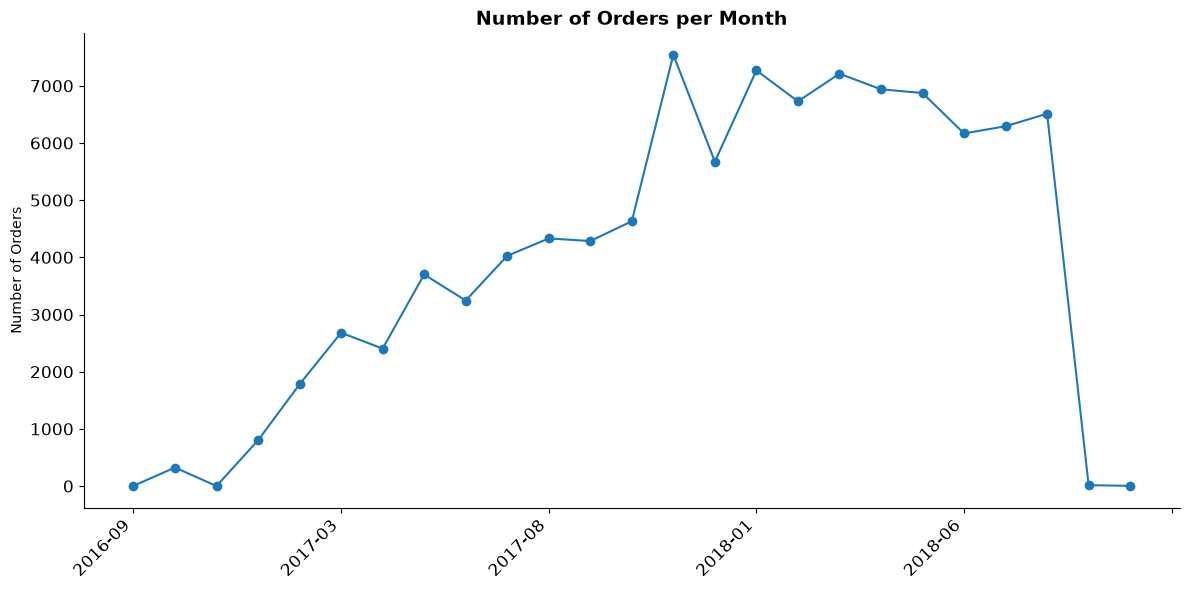

In [2]:
# Question: How many orders were placed each month?
# Note: the first and last months are incomplete (data collection started and ended mid-month).

orders['purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M').astype(str)
monthly_orders = orders['purchase_month'].value_counts().sort_index()

monthly_orders.plot(kind='line', marker='o', fontsize=12, figsize=(12,6))
sns.despine()
plt.title('Number of Orders per Month', fontsize=14, fontweight='bold')
plt.xlabel('')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('images/orders_per_month.png')
plt.show()


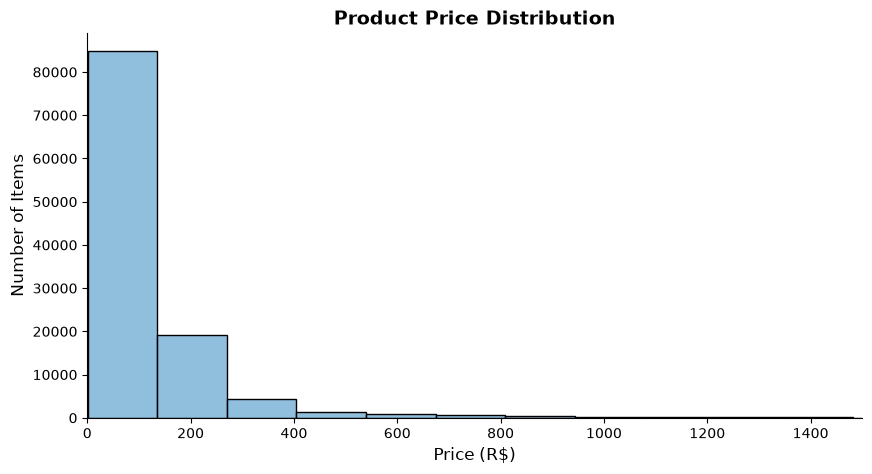

In [3]:
# Question: What does the price distribution look like?
# The distribution has a very long right tail, so the chart stops at the 99th percentile.

plt.figure(figsize=(10,5))
sns.histplot(data=order_items['price'], bins=50, color="#6baad4", edgecolor='black')
sns.despine()

plt.title('Product Price Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Price (R$)', fontsize=12)
plt.ylabel('Number of Items', fontsize=12)
plt.xlim(0, 1500)
plt.savefig('images/product_price_distribution.png')
plt.show()

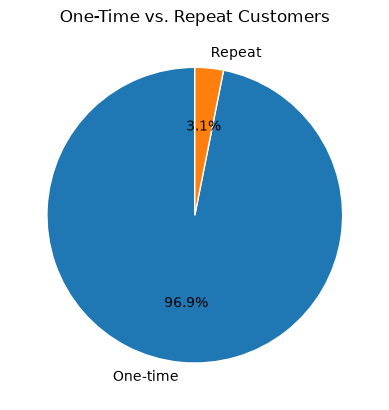

In [4]:
# Question: How many customers bought only once and how many came back?
# customer_id is created for every order, so customer_unique_id identifies the real customer.

orders_customers = orders.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')

orders_per_customer = orders_customers.groupby('customer_unique_id')['order_id'].size()

repeat_counts = pd.Series({
    'One-time': (orders_per_customer == 1).sum(),
    'Repeat': (orders_per_customer > 1).sum(),
})

fig, ax = plt.subplots()
ax.pie(repeat_counts, labels=repeat_counts.index, autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'white'})
ax.set_title('One-Time vs. Repeat Customers')
plt.savefig('images/one_time_vs_repeat_customers.png')
plt.show()

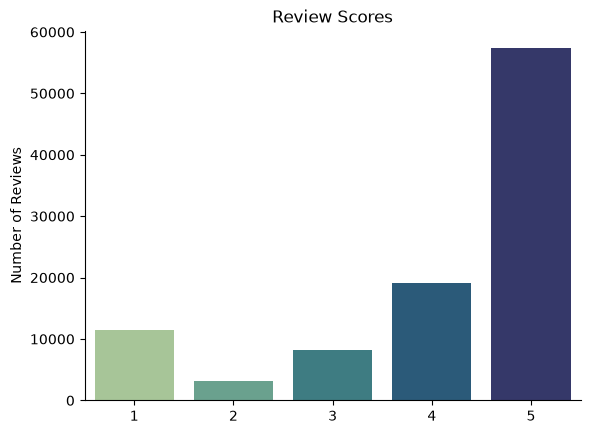

In [5]:
# Question: How do customers rate their orders?

df_plot = reviews['review_score'].value_counts().sort_index().to_frame()

sns.barplot(data=df_plot, x='review_score', y='count', hue='review_score', palette='crest', legend=False)
plt.title('Review Scores')
plt.xlabel('')
plt.ylabel('Number of Reviews')
sns.despine()
plt.savefig('images/review_scores.png')
plt.show()

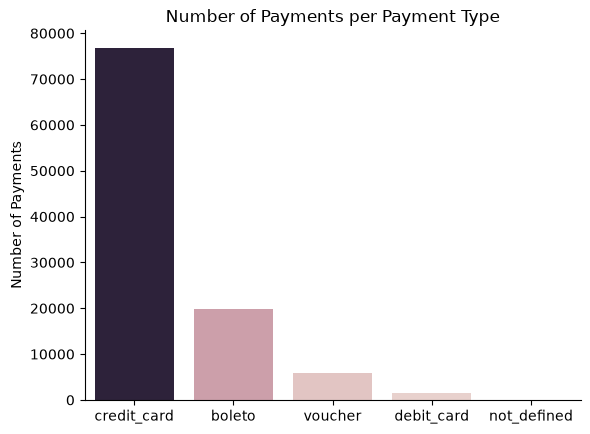

In [6]:
# Question: How do customers pay?

df_plot = payments['payment_type'].value_counts().to_frame()

sns.barplot(data=df_plot, x='payment_type', y='count', hue='count', legend=False)
plt.title('Number of Payments per Payment Type')
plt.xlabel('')
plt.ylabel('Number of Payments')
sns.despine()
plt.savefig('images/payments_per_payment_type.png')
plt.show()

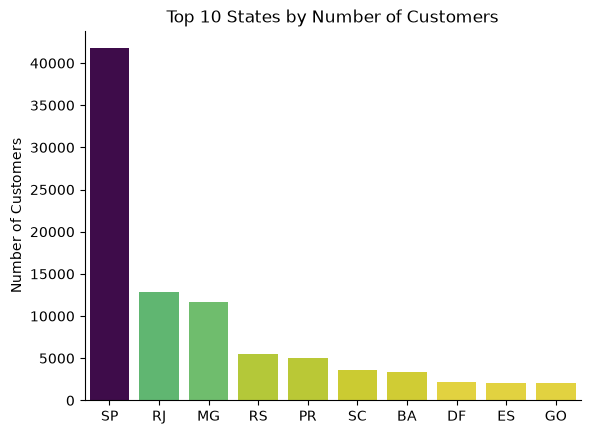

In [8]:
# Question: Which states have the most customers (Top 10)? 

df_plot = customers.groupby('customer_state')['customer_unique_id'].size().sort_values(ascending=False).to_frame().head(10)

sns.barplot(data=df_plot, x='customer_state', y='customer_unique_id', hue='customer_unique_id', palette='viridis_r', legend=False)
plt.title('Top 10 States by Number of Customers')
plt.xlabel('')
plt.ylabel('Number of Customers')
sns.despine()
plt.savefig('images/top_10_states.png')
plt.show()

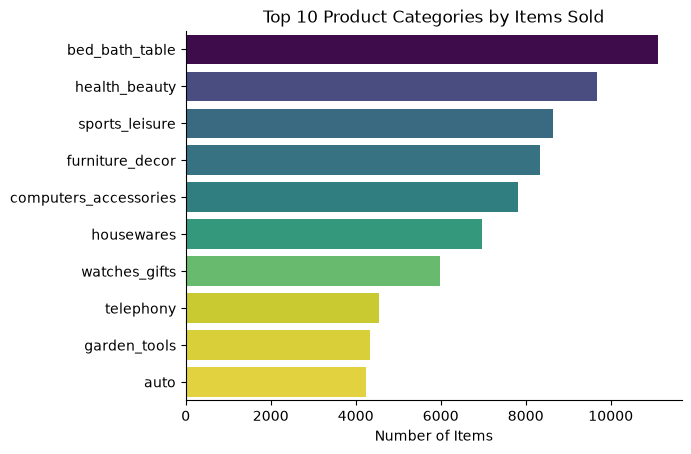

In [55]:
# Question: Which product categories sell the most items?
# Join order items with products and the English category names.

items = order_items.merge(products[['product_id','product_category_name']], on='product_id', how='left')
items = items.merge(category_translation, on='product_category_name', how='left')

df_plot = items['product_category_name_english'].value_counts().head(10).to_frame()

sns.barplot(data=df_plot, x='count', y='product_category_name_english', hue='count', palette='viridis_r', legend=False)
plt.title('Top 10 Product Categories by Items Sold')
plt.xlabel('Number of Items')
plt.ylabel('')
sns.despine()
plt.savefig('images/top_categories.png')
plt.show()

In [22]:
# Question: Which product categories sell the most items?
# Join order items with products and the English category names.
df = products.merge(category_translation['product_category_name'], on='product_category_name')
df = products['product_category_name'].value_counts().head(10)
#df = df.merge(category_translation['product_category_name'], on='product_category_name')
df
#category_translation.head()
#products.head()

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64